# 18 · Verified, Evidence-Grounded Incident Reports (RAG)

**The question:** Can a free local language model write useful incident reports for the detector's alerts, and can we **automatically check every
claim** in those reports against the detector's own evidence and trusted security sources?

| | |
|---|---|
| **Input** | Final detector with calibration (17) and SHAP explanations (16); a knowledge base of official sources; a local LLM (Qwen2.5 7B via Ollama) |
| **What we do** | Build the knowledge base, retrieve relevant passages for each alert, let the LLM write a report with citations, then **verify** each claim |
| **Output** | Verified incident reports, and measurements of how many claims were supported, with and without retrieval (research question **RQ5**) |

### Why verification matters

Language models can state things that sound right but are not supported ("hallucinations"). Existing RAG systems for security reports reduce this
by giving the model sources, but they still do not **check** what the model wrote. Here every claim must cite its evidence, and a checker removes
any claim that its cited evidence does not support.

## 1. Setup

In [1]:
import json
import re
import sys
import time
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src.notebook_helpers import ROOT, TRAIN_CSV, RAW_SHA256, CLASSES, DATA, MODELS, sha256, save_table, save_figure, save_json, read_json, setup_style
from src.final_detector import FinalDetector, prediction_sets, load_raw
from src.explain import RawSpace, shap_values, top_features
from src.rag import build_chunks, Retriever, attack_techniques, ollama_available, ollama_chat, KB
setup_style()
assert sha256(TRAIN_CSV) == RAW_SHA256['train']

LLM = 'qwen2.5:7b'
assert ollama_available(LLM), 'Start Ollama and run: ollama pull qwen2.5:7b'
detector = FinalDetector.load()
calibration = read_json(MODELS / '17_calibration.json')
print('Detector:', detector.name, '| temperature:', round(calibration['temperature'], 3), '| LLM:', LLM)
display(pd.DataFrame(read_json(KB / 'MANIFEST.json')['files']).T[['url', 'bytes']])

Detector: LightGBM (sqrt) | temperature: 1.001 | LLM: qwen2.5:7b


,url,bytes
mitre/enterprise-attack.json,https://raw.githubusercontent.com/mitre/cti/ma...,49253343
nist/NIST.SP.800-61r3.pdf,https://nvlpubs.nist.gov/nistpubs/SpecialPubli...,1040566
nist/NIST.SP.800-94.pdf,https://nvlpubs.nist.gov/nistpubs/Legacy/SP/ni...,1060429
cisa/CISA_Incident_and_Vulnerability_Response_Playbooks.pdf,https://www.cisa.gov/sites/default/files/publi...,2703130


## 2. The knowledge base

Three kinds of official, public sources, split into short passages ("chunks") that can be retrieved and cited:

| Source | What it contributes |
|---|---|
| **MITRE ATT&CK Enterprise** | one passage per attack technique: what it is, which tactic, how to detect it |
| **NIST SP 800-61r3** and **SP 800-94** | incident-response steps and intrusion-detection practice |
| **CISA Incident Response Playbooks** | concrete response procedures used by US federal agencies |

In [2]:
chunks = build_chunks()
chunks.to_csv(KB / 'processed_chunks/chunks.csv', index=False)
display(chunks.groupby('source').agg(passages=('chunk_id', 'size'), average_characters=('text', lambda t: int(t.str.len().mean()))))
retriever = Retriever(chunks)
techniques = attack_techniques().set_index('technique')

,passages,average_characters
source,,
CISA IR Playbooks,121,978
MITRE ATT&CK,706,1190
NIST SP 800-61r3,123,973
NIST SP 800-94,403,1058


## 3. From attack class to ATT&CK techniques

UNSW-NB15 classes are broad. We map each class to the ATT&CK techniques that best describe it, using the dataset creators' class descriptions.
The mapping is written down here, with a confidence level, so a reviewer can check it. "Generic" has no good ATT&CK equivalent (it describes attacks
against block ciphers), and we say so instead of forcing a match.

In [3]:
MAPPING = pd.DataFrame([
    ('DoS', 'T1498, T1499', 'high', 'Attempts to make a service unavailable: network and endpoint denial of service'),
    ('Reconnaissance', 'T1595, T1046', 'high', 'Probing and scanning to gather information about hosts and services'),
    ('Exploits', 'T1190, T1210', 'high', 'Exploiting known vulnerabilities in exposed applications and remote services'),
    ('Fuzzers', 'T1595.002, T1499.004', 'medium', 'Sending random input to find or trigger flaws (vulnerability scanning, crash via exploitation)'),
    ('Worms', 'T1210, T1570', 'medium', 'Self-replicating code that exploits remote services and spreads between hosts'),
    ('Shellcode', 'T1203, T1055', 'medium', 'Small machine-code payloads delivered through exploitation and injected into processes'),
    ('Backdoor', 'T1205, T1571, T1219', 'medium', 'Covert remote access that bypasses normal authentication (signalling, unusual ports, remote access tools)'),
    ('Analysis', 'T1046, T1595', 'low', 'Port scans, spam and HTML-file penetration: closest to service discovery and scanning'),
    ('Generic', 'T1600', 'low', 'Attacks against block ciphers; ATT&CK has no direct match, closest is Weaken Encryption'),
    ('Normal', '', '-', 'No attack'),
], columns=['class', 'techniques', 'confidence', 'rationale'])
MAPPING['names'] = MAPPING.techniques.apply(lambda s: '; '.join(techniques.loc[t.strip(), 'name'] for t in s.split(',') if t.strip()))
assert all(t.strip() in techniques.index for s in MAPPING.techniques for t in s.split(',') if t.strip())
save_table(MAPPING, '18_class_to_attack_mapping')
display(MAPPING[['class', 'techniques', 'names', 'confidence']])
CLASS_TECHNIQUES = {r['class']: [t.strip() for t in r.techniques.split(',') if t.strip()] for _, r in MAPPING.iterrows()}

,class,techniques,names,confidence
0,DoS,"T1498, T1499",Network Denial of Service; Endpoint Denial of ...,high
1,Reconnaissance,"T1595, T1046",Active Scanning; Network Service Discovery,high
2,Exploits,"T1190, T1210",Exploit Public-Facing Application; Exploitatio...,high
3,Fuzzers,"T1595.002, T1499.004",Vulnerability Scanning; Application or System ...,medium
4,Worms,"T1210, T1570",Exploitation of Remote Services; Lateral Tool ...,medium
5,Shellcode,"T1203, T1055",Exploitation for Client Execution; Process Inj...,medium
6,Backdoor,"T1205, T1571, T1219",Traffic Signaling; Non-Standard Port; Remote A...,medium
7,Analysis,"T1046, T1595",Network Service Discovery; Active Scanning,low
8,Generic,T1600,Weaken Encryption,low
9,Normal,,,-


## 4. The evidence package for one alert

For each alert the detector provides **facts**, each with an ID that the report must cite:

- **E1:** predicted class and calibrated probability; **E2:** the conformal prediction set (Notebook 17);
- **E3-E7:** the five columns that pushed the prediction most (SHAP, Notebook 16), with their actual values.

The retriever adds **sources S1-S6**: the passages from the knowledge base that best match the alert.

In [4]:
train_raw, eval_raw = load_raw('train'), load_raw('model_selection')
predictors = [c for c in train_raw.columns if c not in ['id', 'label', 'attack_cat']]
space = RawSpace(train_raw, predictors)
background = space.encode(train_raw.sample(50, random_state=0))
y_eval = pd.Categorical(eval_raw.attack_cat, categories=CLASSES).codes
proba = detector.predict_proba(eval_raw)                       # calibrated
sets = prediction_sets(proba, calibration['class_thresholds'])
predicted = proba.argmax(1)


def evidence_package(i, values_row):
    k = int(predicted[i])
    facts = {'E1': f'Predicted class: {CLASSES[k]} with calibrated probability {proba[i, k]:.2f}',
             'E2': 'Conformal prediction set (90% coverage): ' + ', '.join(CLASSES[j] for j in np.flatnonzero(sets[i]))}
    for n, (name, value) in enumerate(top_features(values_row, k, predictors, k=5), start=3):
        direction = 'supports' if value > 0 else 'argues against'
        facts[f'E{n}'] = f"Column {name} = {eval_raw.iloc[i][name]} {direction} {CLASSES[k]} (SHAP {value:+.3f})"
    techs = CLASS_TECHNIQUES[CLASSES[k]]
    found = pd.concat([retriever.search(' '.join(techniques.loc[t, 'name'] for t in techs) + f' {CLASSES[k]}', k=3, sources=['MITRE ATT&CK']),
                       retriever.search(f'{CLASSES[k]} incident response containment detection network', k=3,
                                        sources=['NIST SP 800-61r3', 'NIST SP 800-94', 'CISA IR Playbooks'])])
    sources = {f'S{n}': row for n, (_, row) in enumerate(found.iterrows(), start=1)}
    return facts, sources

## 5. Which alerts we report on

27 correctly detected attacks (3 per attack class, chosen at random) plus 3 alerts whose prediction set contains **several** classes (ambiguous alerts),
30 alerts in total. SHAP values for these rows are computed exactly as in Notebook 16.

In [5]:
rng = np.random.default_rng(0)
chosen = []
for k in range(10):
    if CLASSES[k] == 'Normal':
        continue
    hits = np.flatnonzero((y_eval == k) & (predicted == k))
    chosen += rng.choice(hits, min(3, len(hits)), replace=False).tolist()
ambiguous = np.flatnonzero((sets.sum(1) > 1) & (predicted != CLASSES.index('Normal')))
chosen += rng.choice(np.setdiff1d(ambiguous, chosen), 3, replace=False).tolist()
alerts = np.array(chosen)
start = time.time()
values, _ = shap_values(detector, space, space.encode(eval_raw.iloc[alerts]), background)
print(f'{len(alerts)} alerts, SHAP in {time.time() - start:.0f} s')

30 alerts, SHAP in 10 s


## 6. The prompt

The model gets the facts and sources and must answer in a fixed JSON format, with citations on every claim. Temperature 0 and a fixed seed make the
output repeatable.

In [6]:
SYSTEM = """You are an assistant for security analysts. Write an incident report about ONE network alert.
Use ONLY the facts (E...) and sources (S...) given. Every claim must cite at least one ID in square-bracket form, e.g. [E1] or [S2].
Do not invent numbers, column names, technique IDs or procedures that are not in the facts or sources.
Write 4 or 5 claims: one about the predicted class and its probability (cite E1), one about the prediction set (cite E2),
and one for each of the three most important columns (cite the fact that names that column: E3, E4 or E5).
Give 1 or 2 ATT&CK techniques whose IDs appear in the sources, and 2 or 3 recommended actions taken from the sources.
Answer with JSON only:
{"summary": "<2 sentences>",
 "claims": [{"text": "<one factual sentence about this alert>", "cites": ["E1"]}],
 "attack_techniques": [{"id": "<ATT&CK ID from the sources>", "cites": ["S1"]}],
 "recommended_actions": [{"text": "<one action>", "cites": ["S4"]}]}"""


def user_prompt(facts, sources, with_sources=True):
    text = 'FACTS:\n' + '\n'.join(f'[{k}] {v}' for k, v in facts.items())
    if with_sources:
        text += '\n\nSOURCES:\n' + '\n'.join(f"[{k}] ({s.source}, {s.location}) {s.text[:900]}" for k, s in sources.items())
    else:
        text += '\n\n(No sources are provided; use your own knowledge for techniques and actions, and cite [E...] where possible.)'
    return text

## 7. The verifier

Each claim is checked with simple, transparent rules. A claim is **supported** only if all apply:

1. **Valid citations:** every cited ID exists in the facts or sources given for this alert.
2. **Facts match:** any column name or probability in the claim matches the cited fact (E...). Column names that are also ordinary English words
   (`service`, `state`, `rate`, `proto`) count only when written like a column (`service = dns`).
3. **Source support:** for claims citing sources, at least half of the claim's content words appear in the cited passages.
4. **Real techniques:** every ATT&CK ID exists in the ATT&CK knowledge base **and** appears in a cited source
   (for reports written without sources: it must at least be one of the techniques mapped to the alert's class).

Unsupported claims are removed from the final report and counted.

In [7]:
ENGLISH_WORDS = {'service', 'state', 'rate', 'proto'}
STOP = set('the a an and or of to in on for with this that is are was were be by as at from it its into via which these those their has have not'.split())


def content_words(text):
    return {w for w in re.findall(r'[a-z0-9_.]+', text.lower()) if len(w) > 3 and w not in STOP}


def check_claim(text, cites, facts, sources):
    if not cites or any(c not in facts and c not in sources for c in cites):
        return False, 'invalid or missing citation'
    cited_facts = ' '.join(facts[c] for c in cites if c in facts)
    for column in set(re.findall(r'\b([a-z_]{3,})\b', text)):
        if column not in predictors:
            continue
        # Common English words (service, state, rate, proto) count as column names only when written like a column: "service = dns"
        if column in ENGLISH_WORDS and not re.search(rf'\b{column}\s*(=|:)|column {column}', text):
            continue
        if column not in cited_facts and not any(column in sources[c].text for c in cites if c in sources):
            return False, f'column {column} not in cited evidence'
    for number in re.findall(r'\b0?\.\d{2}\b', text):
        if number.lstrip('0') not in cited_facts.replace('0.', '.') and cited_facts:
            return False, f'number {number} not in cited facts'
    source_text = ' '.join(sources[c].text for c in cites if c in sources)
    if source_text and not cited_facts:
        words = content_words(text)
        if words and len(words & content_words(source_text)) / len(words) < 0.5:
            return False, 'claim words not found in cited sources'
    return True, 'supported'


def check_technique(tid, cites, sources, class_name):
    if tid not in techniques.index:
        return False, 'not a real ATT&CK ID'
    if sources:                                   # RAG: the ID must appear in a cited passage
        if not any(c in sources and tid in sources[c].text for c in cites):
            return False, 'ID not in cited sources'
    elif tid not in CLASS_TECHNIQUES[class_name]:  # no sources: the ID must at least match the class mapping
        return False, 'ID does not match the alert class'
    return True, 'supported'


def verify(report, facts, sources, class_name):
    rows = []
    for c in report.get('claims', []):
        ok, why = check_claim(c.get('text', ''), c.get('cites', []), facts, sources)
        rows.append({'part': 'claim', 'text': c.get('text', ''), 'supported': ok, 'reason': why})
    for t in report.get('attack_techniques', []):
        ok, why = check_technique(str(t.get('id', '')).strip(), t.get('cites', []), sources, class_name)
        rows.append({'part': 'technique', 'text': str(t.get('id', '')), 'supported': ok, 'reason': why})
    for a in report.get('recommended_actions', []):
        ok, why = check_claim(a.get('text', ''), a.get('cites', []), facts, sources)
        rows.append({'part': 'action', 'text': a.get('text', ''), 'supported': ok, 'reason': why})
    return pd.DataFrame(rows)

## 8. Generate and verify the reports

Each alert gets two reports: one **with retrieved sources (RAG)** and one **without sources** (the model relies on its own memory). Both are verified
with the same rules. This measures what retrieval and verification each add. The model runs locally on the GPU; expect about 10-30 seconds per report.

In [8]:
REPORTS = ROOT / 'reports/generated_incidents'
REPORTS.mkdir(parents=True, exist_ok=True)
results, checks, saved = [], [], {}
for n, i in enumerate(alerts):
    facts, sources = evidence_package(i, values[n])
    for mode in ['RAG', 'no sources']:
        report, raw_text, seconds = ollama_chat(LLM, SYSTEM, user_prompt(facts, sources, with_sources=(mode == 'RAG')))
        if report is None:
            results.append({'alert': int(i), 'mode': mode, 'valid JSON': False, 'seconds': seconds})
            continue
        check = verify(report, facts, sources if mode == 'RAG' else {}, CLASSES[predicted[i]])
        check.insert(0, 'mode', mode); check.insert(0, 'alert', int(i))
        checks.append(check)
        results.append({'alert': int(i), 'true class': CLASSES[y_eval[i]], 'predicted': CLASSES[predicted[i]], 'mode': mode, 'valid JSON': True,
                        'items': len(check), 'supported': int(check.supported.sum()), 'seconds': seconds})
        saved[(int(i), mode)] = (report, facts, sources, check)
    print(f'alert {n + 1}/{len(alerts)} done')
results, checks = pd.DataFrame(results), pd.concat(checks, ignore_index=True)
save_table(results, '18_reports')
save_table(checks, '18_claim_checks')

alert 1/30 done


alert 2/30 done


alert 3/30 done


alert 4/30 done


alert 5/30 done


alert 6/30 done


... (21 outputs left out)

alert 28/30 done


alert 29/30 done


alert 30/30 done


WindowsPath('D:/projects/Botnet attack detection/results/tables/v3/18_claim_checks.csv')

## 9. How many claims were supported?

items  share supported
mode       part                             
RAG        action        58           0.5345
           claim        140           0.9929
           technique     36           1.0000
no sources action        60           0.1833
           claim        137           0.9854
           technique     57           0.0877

,reports,valid_json,seconds_per_report
mode,,,
RAG,30,1.0000,10.5131
no sources,30,1.0000,8.9503


unsupported items
mode       reason                                                   
RAG        claim words not found in cited sources                  2
           column sttl not in cited evidence                       1
           invalid or missing citation                            25
no sources ID does not match the alert class                      45
           column sbytes not in cited evidence                     1
           invalid or missing citation                            50
           not a real ATT&CK ID                                    7

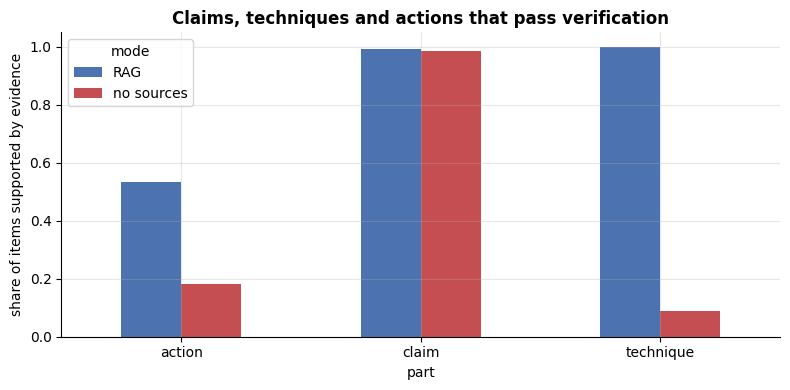

In [9]:
summary = checks.groupby(['mode', 'part']).supported.agg(['size', 'mean']).rename(columns={'size': 'items', 'mean': 'share supported'})
display(summary)
display(results.groupby('mode').agg(reports=('alert', 'size'), valid_json=('valid JSON', 'mean'), seconds_per_report=('seconds', 'mean')))
display(checks[~checks.supported].groupby(['mode', 'reason']).size().rename('unsupported items').to_frame())

fig, ax = plt.subplots(figsize=(8, 4))
pivot = checks.groupby(['part', 'mode']).supported.mean().unstack()
pivot.plot.bar(ax=ax, rot=0, color=['#4C72B0', '#C44E52'])
ax.set(ylabel='share of items supported by evidence', ylim=(0, 1.05), title='Claims, techniques and actions that pass verification')
plt.tight_layout(); save_figure(fig, '18_verification'); plt.show()

In [10]:
# This run's key numbers (the local LLM's wording varies slightly between runs, so the text below refers to these printed values).
share = checks.groupby(['mode', 'part']).supported.mean()
fake = int(((checks['mode'] == 'no sources') & (checks.reason == 'not a real ATT&CK ID')).sum())
print(f"RAG: claims {share['RAG', 'claim']:.1%}, techniques {share['RAG', 'technique']:.1%}, actions {share['RAG', 'action']:.1%} supported")
print(f"No sources: claims {share['no sources', 'claim']:.1%}, techniques {share['no sources', 'technique']:.1%}, actions {share['no sources', 'action']:.1%} supported; "
      f"{fake} technique IDs that do not exist in ATT&CK")

RAG: claims 99.3%, techniques 100.0%, actions 53.4% supported
No sources: claims 98.5%, techniques 8.8%, actions 18.3% supported; 7 technique IDs that do not exist in ATT&CK


**What we see** (exact numbers in the printout above):

- **With retrieval (RAG), almost every factual claim and technique passes** the checks (in our runs: claims about 99%, techniques 97-100%).
  Each report contains about 8 checked items.
- **Without sources, the model invents things:** several technique IDs that **do not exist in ATT&CK** (7-8 per run of 30 reports), and many more that
  do not match the alert's class; only about 10% of its technique choices are acceptable.
- **The weak point of RAG reports is the recommended actions** (about half pass): mostly the model wrote an action **without citing** a source.
  Section 10 lets the model repair these.
- Each report takes about 10 seconds on the local GPU, and every answer was valid JSON.
- **Run-to-run variation:** even with temperature 0 and a fixed seed, the local model's wording changes slightly between runs (GPU arithmetic is not
  perfectly repeatable). The shares move by a few points; the conclusions do not change.

**Limitation:** the verifier checks citations, numbers, column names and technique IDs. It does **not** check meaning. For example, a sentence saying a
prediction set "suggests a high likelihood" of one class can pass even though the set contains four classes. That is why the summary of each report is
built directly from the evidence instead of being written by the model.

## 10. Repairing unsupported items

Deleting unsupported items keeps reports correct but loses content. So the model gets **one chance to repair** each report: it receives its failed
items with the verifier's reasons, and must either add a citation that really supports the item or remove it. The repaired report is **verified again
with the same rules**; anything still unsupported is removed.

In [11]:
REPAIR = """Some items of your previous report failed verification; each failed item comes with the reason.
Rewrite each failed item so that it cites a fact (E...) or source (S...) that really supports it, or remove the item if nothing supports it.
Keep all items that passed. Answer with the complete corrected report in the same JSON format."""
repaired, after = {}, []
for (alert, mode), (report, facts, sources, check) in saved.items():
    if mode != 'RAG':
        continue
    new_report, new_check = report, check
    if not check.supported.all():
        failed = check[~check.supported][['part', 'text', 'reason']].to_dict('records')
        prompt = user_prompt(facts, sources) + '\n\nYOUR PREVIOUS REPORT:\n' + json.dumps(report) + '\n\nFAILED ITEMS:\n' + json.dumps(failed)
        candidate, _, _ = ollama_chat(LLM, SYSTEM + '\n' + REPAIR, prompt)
        if candidate is not None:
            new_report, new_check = candidate, verify(candidate, facts, sources, CLASSES[predicted[alert]])
    repaired[alert] = (new_report, facts, sources, new_check)
    after.append(new_check.assign(alert=alert))
after = pd.concat(after, ignore_index=True)
save_table(after, '18_claim_checks_after_repair')
before_after = pd.DataFrame({
    'supported items per report, before repair': checks[checks['mode'] == 'RAG'].groupby('alert').supported.sum().mean(),
    'supported items per report, after repair': after.groupby('alert').supported.sum().mean(),
    'share supported, before': checks[checks['mode'] == 'RAG'].supported.mean(),
    'share supported, after': after.supported.mean()}, index=['RAG reports'])
display(before_after.round(3))
display(after.groupby('part').supported.agg(['size', 'mean']).rename(columns={'size': 'items', 'mean': 'share supported after repair'}).round(3))

,"supported items per report, before repair","supported items per report, after repair","share supported, before","share supported, after"
RAG reports,6.8670,6.9330,0.8800,0.8930


,items,share supported after repair
part,,
action,59,0.5930
claim,138,0.9930
technique,36,1.0000


**What we see:** the repair step lets the model fix its own uncited items. The table above shows how many supported items each report keeps before
and after repair; whatever still fails is removed, so the final reports contain **only verified statements**.

## 11. One verified report

The final report keeps only supported items. Each line shows its citations, so an analyst can trace every statement.

In [12]:
def render(alert):
    report, facts, sources, check = repaired[alert]
    ok = check.set_index(['part', 'text']).supported
    in_set = [CLASSES[j] for j in np.flatnonzero(sets[alert])]
    # The summary is built from the evidence itself (not written by the LLM), so the report contains no unchecked sentence.
    summary = (f"The detector flags this flow as **{CLASSES[predicted[alert]]}** (calibrated probability {proba[alert, predicted[alert]]:.2f}). "
               + ('It is confident: the prediction set contains only this class.' if len(in_set) == 1
                  else f"The attack type is uncertain: the prediction set contains {', '.join(in_set)}."))
    lines = [f"### Incident report: alert {alert} ({CLASSES[predicted[alert]]})", '', summary, '', '**Evidence**']
    lines += [f"- [{k}] {v}" for k, v in facts.items()]
    lines += ['', '**Verified findings**'] + [f"- {c['text']} {c.get('cites', [])}" for c in report.get('claims', []) if ok.get(('claim', c.get('text', '')), False)]
    lines += ['', '**ATT&CK techniques**'] + [f"- {t['id']} {techniques.loc[t['id'], 'name'] if t['id'] in techniques.index else ''} {t.get('cites', [])}"
                                              for t in report.get('attack_techniques', []) if ok.get(('technique', str(t.get('id', ''))), False)]
    lines += ['', '**Recommended actions**'] + [f"- {a['text']} {a.get('cites', [])}" for a in report.get('recommended_actions', [])
                                                if ok.get(('action', a.get('text', '')), False)]
    lines += ['', '**Sources**'] + [f"- [{k}] {s.source}, {s.location}" for k, s in sources.items()]
    removed = int((~check.supported).sum())
    lines += ['', f'*After one repair round, {removed} unsupported item(s) were still removed by the verifier.*']
    return '\n'.join(lines)


example = int(alerts[0])
display(Markdown(render(example)))
for alert in repaired:
    (REPORTS / f'alert_{alert}.md').write_text(render(alert), encoding='utf-8')
print(f'Saved {len(repaired)} verified (repaired) reports to reports/generated_incidents/')

### Incident report: alert 8270 (Analysis)

The detector flags this flow as **Analysis** (calibrated probability 1.00). It is confident: the prediction set contains only this class.

**Evidence**
- [E1] Predicted class: Analysis with calibrated probability 1.00
- [E2] Conformal prediction set (90% coverage): Analysis
- [E3] Column ct_flw_http_mthd = 30 supports Analysis (SHAP +0.369)
- [E4] Column ackdat = 0.187635 supports Analysis (SHAP +0.159)
- [E5] Column response_body_len = 156 supports Analysis (SHAP +0.132)
- [E6] Column proto = tcp supports Analysis (SHAP +0.125)
- [E7] Column sttl = 62 supports Analysis (SHAP +0.100)

**Verified findings**
- The alert has a predicted class of Analysis with a calibrated probability of 1.00, indicating a high confidence level. ['E1']
- The prediction set includes only the class 'Analysis', suggesting this is the primary focus of the alert. ['E2']
- The column 'ct_flw_http_mthd' with a value of 30 supports the Analysis prediction, contributing +0.369 to the SHAP value. ['E3']
- The column 'response_body_len' with a value of 156 also supports the Analysis prediction, adding +0.132 to the SHAP value. ['E5']

**ATT&CK techniques**
- T1007 System Service Discovery ['S1']
- T1595 Active Scanning ['S2']

**Recommended actions**

**Sources**
- [S1] MITRE ATT&CK, T1007
- [S2] MITRE ATT&CK, T1595
- [S3] MITRE ATT&CK, T1046
- [S4] CISA IR Playbooks, page 31
- [S5] CISA IR Playbooks, page 2
- [S6] CISA IR Playbooks, page 31

*After one repair round, 2 unsupported item(s) were still removed by the verifier.*

Saved 30 verified (repaired) reports to reports/generated_incidents/


## 12. Save

In [13]:
save_json({'llm': LLM, 'alerts': [int(a) for a in alerts], 'retrieval': 'TF-IDF (1-2 grams), 3 ATT&CK + 3 guidance passages per alert',
           'verifier_rules': ['valid citations', 'facts match', 'at least half of content words in cited sources', 'real ATT&CK IDs present in cited sources'],
           'knowledge_base': read_json(KB / 'MANIFEST.json')}, MODELS / '18_rag_settings.json')
assert sha256(TRAIN_CSV) == RAW_SHA256['train']
print('Saved settings, reports and claim checks.')

Saved settings, reports and claim checks.


## Summary

### What we learned

| Question | Answer |
|---|---|
| Can a free local LLM write incident reports? | Yes: Qwen2.5 7B via Ollama, about 10 s per report on the laptop GPU, always valid JSON |
| Does retrieval help? (RQ5, H4) | **Yes, clearly:** with retrieval 97-100% of techniques are supported; without it the model **invents ATT&CK IDs** (7-8 non-existent IDs per 30 reports, plus many wrong-class IDs) |
| Are the claims supported? | With retrieval, about 99% of factual claims pass the checks |
| What fails most? | Recommended actions written without citations (about half pass at first) |
| Does a repair round help? | The model fixes part of its uncited items; whatever still fails is removed, so final reports contain only verified statements (Section 10) |
| What can the verifier not do? | Check meaning; it checks citations, values, columns and IDs |

### What this means for the paper

Hypothesis **H4 is supported**: verified, retrieval-grounded reports contain far fewer unsupported statements than reports written from the model's own
memory, and the remaining unsupported items are detected and removed automatically. This is contribution **C5**: every statement an analyst reads can be
traced to the detector's evidence (probability, prediction set, SHAP columns) or to an official source (ATT&CK, NIST, CISA).

### What is still uncertain

- 30 alerts is a small sample; a larger evaluation and a human analyst review of report quality would strengthen the claim.
- The class-to-ATT&CK mapping is our own documented judgement (confidence high / medium / low per class).

### What comes next

**Notebook 19** evaluates the final detector once on the official test file.